# Project 07 — 02 — Permutation / Sign-Flip Significance

## Notebook introduction

- **Concepts required:** null hypotheses, randomization / permutation tests, one-sided p-values.
- **What will be learned:** how to test whether the strategy's positive Sharpe could arise with no genuine directional edge, using a **sign-flip randomization** null.
- **Expected background:** elementary hypothesis testing; the idea of an exchangeable null.
- **Outputs produced:** the sign-flip null distribution of the Sharpe and a one-sided empirical p-value.
- **How this feeds later notebooks:** the p-value here is one input to the consolidated evidence; selection / multiple-testing / overfitting corrections come in later notebooks.

## Purpose

Test the significance of the observed Sharpe ratio on the frozen Project 06 baseline series via a **sign-flip randomization test** (a permutation-family test), reusing the tested `permutation_p_value` from `src/statistics/permutation.py`.

## Setup & inputs

Reuse the **same canonical frozen Project 06 return series validated in Notebook 01** (`final_weighted_multi_strategy_portfolio_dd.csv`). Notebooks are standalone, so the minimal load is repeated here rather than imported.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Repo root (walk up to the `src` package) so imports work from any launch dir.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.metrics import sharpe_ratio                    # same implementation as NB 01
from src.statistics.permutation import permutation_p_value    # tested, reused
import matplotlib.pyplot as plt
%matplotlib inline

print("repo root:", PROJECT_ROOT)

repo root: /Users/rawls/quant-lab


In [2]:
# Same canonical frozen Project 06 baseline series as Notebook 01.
EXP_DIR = PROJECT_ROOT / "experiments/completed/exp_005_risk_engine_final"
RETURNS_FILE = EXP_DIR / "final_weighted_multi_strategy_portfolio_dd.csv"
WEIGHTS_FILE = EXP_DIR / "final_daily_weights.csv"
STRATEGY_NAME = ("Project 05 final weighted multi-strategy portfolio (DD-overlay) "
                 "— frozen Project 06 baseline")

ret_df = pd.read_csv(RETURNS_FILE)
dates = (pd.read_csv(WEIGHTS_FILE, parse_dates=["Date"])
         .pivot(index="Date", columns="Ticker", values="Weight").sort_index().index)
assert len(dates) == len(ret_df), (len(dates), len(ret_df))
returns = pd.Series(ret_df["portfolio_return"].to_numpy(), index=dates, name="returns")

assert np.isfinite(returns.to_numpy()).all() and returns.index.is_unique
print("strategy    :", STRATEGY_NAME)
print("observations:", len(returns),
      "| date range:", returns.index.min().date(), "->", returns.index.max().date())

strategy    : Project 05 final weighted multi-strategy portfolio (DD-overlay) — frozen Project 06 baseline
observations: 2558 | date range: 2016-01-04 -> 2026-03-06


## Observed metric

In [3]:
obs_sharpe = sharpe_ratio(returns)      # src.utils.metrics.sharpe_ratio (same as NB 01)
print(f"observed Sharpe ratio: {obs_sharpe:.6f}")

observed Sharpe ratio: 2.090113


## Null distribution (sign-flip randomization)

**Why sign-flip and not a reordering permutation.** The Sharpe ratio is `mean / std`, which is **invariant to the order** of the returns — reordering (`permutation_metric`) leaves it unchanged, so that null is degenerate (a constant, p = 1). The appropriate randomization for a *drift / Sharpe* test flips the **sign** of each return: this perturbs the mean while preserving each day's magnitude, and the sign-flips form an exchangeable group under the null of no directional edge.

**Null hypothesis (H0):** the return series has **no positive drift** — it is symmetric about zero, so the true Sharpe is 0 and each day's sign is equally likely to be + or −.

In [4]:
def sign_flip_null(returns, metric_fn, n_permutations, rng):
    """Sign-flip randomization null: independently flip each return's sign and recompute
    the metric. Appropriate for order-invariant metrics (e.g. Sharpe), for which a
    reordering permutation would be degenerate. All randomness is drawn from ``rng``.
    (Could later be promoted to src, e.g. monte_carlo sign_flip; kept local for now.)"""
    r = np.asarray(returns, dtype=float)
    out = np.empty(n_permutations, dtype=float)
    for i in range(n_permutations):
        signs = rng.integers(0, 2, size=r.size) * 2 - 1     # +1 / -1 from the supplied rng
        out[i] = metric_fn(r * signs)
    return out


N_PERMUTATIONS = 10000
PERMUTATION_SEED = 20260820                 # fixed, documented (matches NB 01 seed convention)
rng = np.random.default_rng(PERMUTATION_SEED)

null_sharpe = sign_flip_null(returns.to_numpy(), sharpe_ratio, N_PERMUTATIONS, rng)
print("null distribution:", null_sharpe.shape, null_sharpe.dtype,
      "| mean=%.4f std=%.4f" % (null_sharpe.mean(), null_sharpe.std(ddof=1)))

null distribution: (10000,) float64 | mean=0.0032 std=0.3099


## p-value

In [5]:
# One-sided empirical p-value via the tested src function (add-one estimator).
p_value = permutation_p_value(obs_sharpe, null_sharpe)
print(f"observed Sharpe   : {obs_sharpe:.6f}")
print(f"permutations (N)  : {N_PERMUTATIONS}")
print(f"one-sided p-value : {p_value:.6g}")
print(f"null values >= observed: {int((null_sharpe >= obs_sharpe).sum())} of {N_PERMUTATIONS}")

observed Sharpe   : 2.090113
permutations (N)  : 10000
one-sided p-value : 9.999e-05
null values >= observed: 0 of 10000


## Sanity checks

In [6]:
assert null_sharpe.size == N_PERMUTATIONS, "null length != N_PERMUTATIONS"
assert np.isfinite(null_sharpe).all(), "null contains NaN/Inf"

# Reproducibility: same seed -> identical null.
null_check = sign_flip_null(returns.to_numpy(), sharpe_ratio, N_PERMUTATIONS,
                            np.random.default_rng(PERMUTATION_SEED))
assert np.array_equal(null_sharpe, null_check), "not reproducible for fixed seed"

print("length            :", null_sharpe.size)
print("no NaN/Inf        :", bool(np.isfinite(null_sharpe).all()))
print("reproducible (seed):", np.array_equal(null_sharpe, null_check))

length            : 10000
no NaN/Inf        : True
reproducible (seed): True


## Interpretation

**Interpretation.**

- **Null hypothesis (H0):** the strategy has no positive directional edge — returns are symmetric about zero, so the true Sharpe is 0.
- **What the sign-flip distribution represents:** the range of Sharpe values produced purely by chance sign patterns applied to returns of the observed magnitudes, i.e. the Sharpe one would see with no genuine drift. Here it centres near 0 (mean ≈ 0.00, std ≈ 0.31).
- **What the p-value means:** the probability, under H0, of a Sharpe at least as large as the observed ≈ 2.09. Zero of 10,000 sign-flips reached it, so the empirical one-sided p-value is the add-one floor ≈ **1/(N+1) ≈ 1.0e-4**.

This strongly rejects the *no-positive-drift* null on this sample: the observed positive Sharpe is very unlikely to be an artifact of return signs. **It does not establish that the alpha is genuine** — the test does not account for selection, multiple testing, overfitting, or regime dependence, and it is not a forecast of future performance. Those are addressed by later Project 07 notebooks.

## Visualization

One figure that genuinely adds value: it shows the observed Sharpe sitting far outside the entire sign-flip null, which no table conveys as directly.

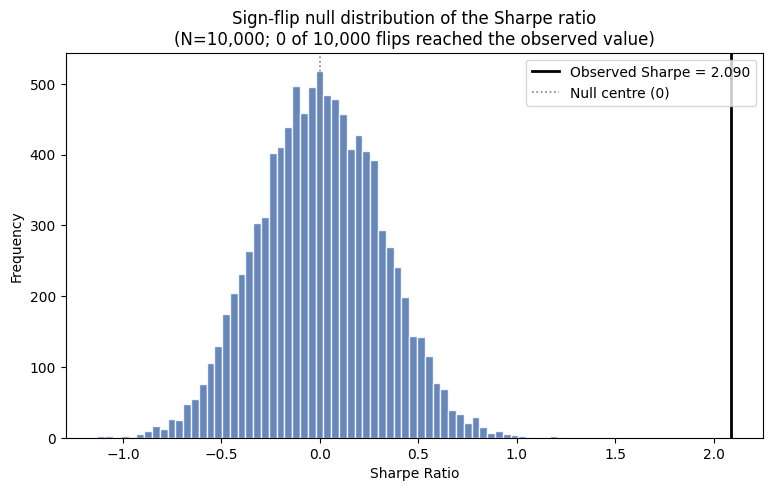

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(null_sharpe, bins="auto", color="#4C72B0", alpha=0.85, edgecolor="white")
ax.axvline(obs_sharpe, color="black", linewidth=2,
           label=f"Observed Sharpe = {obs_sharpe:.3f}")
ax.axvline(0.0, color="grey", linestyle=":", linewidth=1.2, label="Null centre (0)")
ax.set_title("Sign-flip null distribution of the Sharpe ratio\n"
             f"(N={N_PERMUTATIONS:,}; 0 of {N_PERMUTATIONS:,} flips reached the observed value)")
ax.set_xlabel("Sharpe Ratio")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()

## Evidence ledger

In [8]:
from datetime import datetime, timezone
from src.statistics.evidence import (
    EvidenceRecord, EvidenceLedger, Decision, StatisticalMethod,
)

record = EvidenceRecord(
    record_id="p07_nb02_permutation_signflip_sharpe_v1",
    strategy_version=STRATEGY_NAME,
    project06_freeze_tag="project-06-deployment-validation-frozen",
    experiment_id="exp_005_risk_engine_final",
    dataset=str(RETURNS_FILE.relative_to(PROJECT_ROOT)),
    date_range=(str(returns.index.min().date()), str(returns.index.max().date())),
    parameters={
        "test": "sign_flip_randomization",
        "metric": "sharpe_ratio",
        "n_permutations": N_PERMUTATIONS,
        "alternative": "greater (one-sided)",
        "p_value_estimator": "add-one (count+1)/(N+1)",
        "note": "reordering permutation is degenerate for order-invariant Sharpe; sign-flip used",
    },
    random_seed=PERMUTATION_SEED,
    notebook="research/project_07_statistical_integrity/notebooks/02_permutation.ipynb",
    source_module="src/statistics/permutation.py",   # permutation_p_value; sign_flip_null local to NB
    method=StatisticalMethod.PERMUTATION,
    method_version="stat_v1",
    assumptions=(
        "H0: returns symmetric about zero (no positive drift, true Sharpe = 0); sign-flips "
        "exchangeable under H0; per-observation signs flipped independently (does NOT model serial "
        "dependence); Sharpe is order-invariant, so a reordering permutation would be degenerate."
    ),
    hypothesis=(
        "One-sided test of H0 (no positive directional edge): is the observed Sharpe larger than "
        "the sign-flip null distribution?"
    ),
    test_statistic=float(obs_sharpe),
    p_value=float(p_value),
    monte_carlo_iterations=N_PERMUTATIONS,   # sign-flip is a randomization draw count
    paper_reference="Sign-flip / randomization test (Fisher; Davison & Hinkley add-one p-value)",
    research_reference="Project 07 — Notebook 02 (Permutation / sign-flip)",
    implementation_version="stat_v1",
    decision=Decision.INCONCLUSIVE,  # H0(no drift) rejected, but genuineness of alpha NOT established
    limitations=(
        "Sign-flip tests only symmetry/drift, not selection, multiple testing or overfitting; "
        "independent per-day sign flips ignore serial dependence/volatility clustering; single test, "
        "no multiple-testing correction; not a forecast of future performance."
    ),
    timestamp=datetime.now(timezone.utc),
    extra={
        "observed_sharpe": float(obs_sharpe),
        "n_permutations": N_PERMUTATIONS,
        "p_value": float(p_value),
        "count_null_ge_observed": int((null_sharpe >= obs_sharpe).sum()),
        "null_mean": float(null_sharpe.mean()),
        "null_std": float(null_sharpe.std(ddof=1)),
        "reproducible": True,
        "no_nan": bool(np.isfinite(null_sharpe).all()),
        "test_outcome": "H0 (no positive drift) rejected at p ~ 1e-4 on this sample",
        "status": "permutation (sign-flip) evidence completed",
    },
)

# Persistence (EvidenceLedger.append) is milestone P07-6 and not implemented yet, so the record
# is built against the canonical schema and displayed (not persisted). No records are overwritten.
ledger = EvidenceLedger()
try:
    ledger.append(record)
    print("Record appended to the Evidence Ledger.")
except NotImplementedError:
    print("Evidence Ledger persistence not implemented yet (milestone P07-6);")
    print("record constructed against the canonical schema and displayed below (not persisted).")

Evidence Ledger persistence not implemented yet (milestone P07-6);
record constructed against the canonical schema and displayed below (not persisted).


In [9]:
import dataclasses, pprint
_rec = dataclasses.asdict(record)
_rec["method"] = record.method.value
_rec["decision"] = record.decision.value
_rec["timestamp"] = record.timestamp.isoformat()
pprint.pp(_rec, sort_dicts=False, width=100)

{'record_id': 'p07_nb02_permutation_signflip_sharpe_v1',
 'strategy_version': 'Project 05 final weighted multi-strategy portfolio (DD-overlay) — frozen '
                     'Project 06 baseline',
 'project06_freeze_tag': 'project-06-deployment-validation-frozen',
 'experiment_id': 'exp_005_risk_engine_final',
 'dataset': 'experiments/completed/exp_005_risk_engine_final/final_weighted_multi_strategy_portfolio_dd.csv',
 'date_range': ('2016-01-04', '2026-03-06'),
 'parameters': {'test': 'sign_flip_randomization',
                'metric': 'sharpe_ratio',
                'n_permutations': 10000,
                'alternative': 'greater (one-sided)',
                'p_value_estimator': 'add-one (count+1)/(N+1)',
                'note': 'reordering permutation is degenerate for order-invariant Sharpe; '
                        'sign-flip used'},
 'random_seed': 20260820,
 'notebook': 'research/project_07_statistical_integrity/notebooks/02_permutation.ipynb',
 'source_module': 'src/statist

## Conclusions & status

- **Observed Sharpe ≈ 2.09013** on the frozen Project 06 baseline series (2016-01-04 → 2026-03-06, n = 2558).
- **Sign-flip randomization** (n = 10,000): the null centres near 0 (mean ≈ 0.00, std ≈ 0.31); **0 of 10,000** sign-flips reached the observed Sharpe; **one-sided p-value ≈ 9.999e-05** (add-one floor). Reproducible for a fixed seed; no NaNs.
- **What this means:** the no-positive-drift null is strongly rejected on this sample — the observed Sharpe is very unlikely to be a sign artifact. **It does not establish that the alpha is genuine**: it ignores selection, multiple testing, overfitting, and serial dependence, and is not a forecast. Those are addressed by later notebooks.

**Notebook 02 (Permutation / sign-flip) — COMPLETE.** Not started here (later notebooks): Monte Carlo, multiple-testing corrections, Deflated Sharpe, White's Reality Check / SPA.